# Домашняя работа. Метрики магазина «Мякушка»

«Мякушка» — сеть пекарен, которая продаёт хлеб и выпечку через приложение и сайт. Магазин работает в нескольких городах России. Пользователи заходят в приложение, просматривают товары и оформляют заказы.

Команда «Мякушки» готовит отчёт за июнь 2026 года. Вам передали выгрузку пользовательских событий и попросили подготовить короткий аналитический отчёт: посчитать показатели за месяц, исследовать динамику revenue по городам и сравнить покупателей Москвы и Казани.

Домашняя работа состоит из **трёх обязательных заданий и одного дополнительного**. В каждом задании оставьте код, результат его выполнения и ответ на вопрос задания.

## Ход исследования

Исследование пройдёт в три этапа:

- расчёт месячных показателей
- анализ подневной динамики revenue по городам
- сравнение покупателей Москвы и Казани

Выполните расчёты и оставьте после каждого этапа короткий вывод. Код должен запускаться последовательно без ошибок.

## Начало работы

Импортируйте библиотеки. Затем найдите файл `myakushka_events.csv`, скопируйте путь к нему и вставьте внутрь кавычек в следующей ячейке.

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

In [ ]:
# Замените текст внутри кавычек своим путём к файлу
data_path = "myakushka_events.csv"

df = pd.read_csv(data_path)
df.head()

,event_timestamp,user_id,city,event_type,order_id,revenue,source,platform
0,2026-06-01 02:01:45,TEST-KZN-0001,Казань,purchase,TEST-00001,unknown,test,android
1,2026-06-01 02:01:49,TEST-KZN-0121,Казань,purchase,TEST-00121,110.00,test,android
2,2026-06-01 02:31:18,TEST-KZN-0031,Казань,purchase,TEST-00031,110.00,test,android
3,2026-06-01 03:01:47,TEST-KZN-0061,Казань,purchase,TEST-00061,110.00,test,ios
4,2026-06-01 03:31:47,TEST-KZN-0091,Казань,purchase,TEST-00091,110.00,test,android


## Структура данных

Одна строка таблицы — одно событие пользователя в приложении.

| Столбец | Содержание |
|---|---|
| `event_timestamp` | дата и время события |
| `user_id` | идентификатор пользователя |
| `city` | город пользователя |
| `event_type` | тип события: визит, просмотр товара или покупка |
| `order_id` | идентификатор заказа; заполнен для событий покупки |
| `revenue` | выручка; для событий без покупки обычно равна 0 |
| `source` | канал привлечения или служебная метка: `organic`, `ads`, `referral`, `test` |
| `platform` | платформа: Android, iOS или web |

О качестве данных ничего не известно. Перед расчётами убедитесь, что столбцы, необходимые для анализа, заполнены и имеют подходящий формат.

## Задание 1. Посчитайте показатели за месяц

Рассчитайте четыре показателя магазина за июнь:

- **Revenue** — выручка магазина от покупок
- **MAU** — количество пользователей, которые хотя бы раз заходили в приложение за месяц
- **Buyers** — количество пользователей, которые хотя бы раз совершили покупку за месяц
- **Orders** — количество оформленных заказов за месяц

Перед расчётом посмотрите на столбцы, от которых зависят эти показатели, и проверьте, всё ли в порядке с их качеством. Подготовьте данные так, чтобы найденные проблемы не искажали итоговые значения.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10772 entries, 0 to 10771
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   event_timestamp  10772 non-null  object
 1   user_id          10772 non-null  object
 2   city             10772 non-null  object
 3   event_type       10772 non-null  object
 4   order_id         1326 non-null   object
 5   revenue          10772 non-null  object
 6   source           10772 non-null  object
 7   platform         10772 non-null  object
dtypes: object(8)
memory usage: 673.4+ KB


In [ ]:
# Приводим дату и время к формату datetime
df["event_timestamp"] = pd.to_datetime(
    df["event_timestamp"],
    errors="coerce"
)
# Приводим выручку к числовому формату
df["revenue"] = pd.to_numeric(
    df["revenue"],
    errors="coerce"
)

# Для событий без покупки выручка равна 0
df["revenue"] = df["revenue"].fillna(0)

# Удаляем строки, в которых невозможно определить дату или пользователя
df = df.dropna(
    subset=["event_timestamp","user_id"]
)

# Оставляем только корректные события
df = df[df["event_type"].notna()]

df.head(10)



,event_timestamp,user_id,city,event_type,order_id,revenue,source,platform
0,2026-06-01 02:01:45,TEST-KZN-0001,Казань,purchase,TEST-00001,0.0,test,android
1,2026-06-01 02:01:49,TEST-KZN-0121,Казань,purchase,TEST-00121,110.0,test,android
2,2026-06-01 02:31:18,TEST-KZN-0031,Казань,purchase,TEST-00031,110.0,test,android
3,2026-06-01 03:01:47,TEST-KZN-0061,Казань,purchase,TEST-00061,110.0,test,ios
4,2026-06-01 03:31:47,TEST-KZN-0091,Казань,purchase,TEST-00091,110.0,test,android
5,2026-06-01 08:03:46,NSK-0009,Новосибирск,visit,NaN,0.0,ads,android
6,2026-06-01 08:08:18,NSK-0009,Новосибирск,product_view,NaN,0.0,ads,android
7,2026-06-01 08:11:12,SPB-0071,Санкт-Петербург,visit,NaN,0.0,referral,android
8,2026-06-01 08:15:32,NSK-0020,Новосибирск,visit,NaN,0.0,organic,android
9,2026-06-01 08:17:25,KZN-0010,Казань,visit,NaN,0.0,ads,android


### Обоснование подготовки данных

_Напишите, какие проблемы вы нашли в столбцах, необходимых для расчёта, что изменили и почему._

In [ ]:
'''
1. Cтолбец event_timestamp необходимо привести к формату даты и времени - pd.to_datetime()
2. В столбце revenue встречаются значения, которые необходимо привести к числовому формату
   Некорректные и отсутствующие значения заменены на 0, поскольку для событий без покупки выручка отсутствует
3. Строки без event_timestamp или user_id удалены, так как без даты нельзя определить месяц события.
   Без идентификатора пользователя невозможно корректно рассчитать MAU и количество покупателей.

'''

'\n1. Cтолбец event_timestamp необходимо привести к формату даты и времени - pd.to_datetime()\n2. В столбце revenue встречаются значения, которые необходимо привести к числовому формату\n   Некорректные и отсутствующие значения заменены на 0, поскольку для событий без покупки выручка отсутствует\n3. Строки без event_timestamp или user_id удалены, так как без даты нельзя определить месяц события.\n   Без идентификатора пользователя невозможно корректно рассчитать MAU и количество покупателей.\n\n'

In [ ]:
# Ваш код для расчета показателей

# Фильтруем данные за июнь 2026 года
june = df[
    (df["event_timestamp"] >= "2026-06-01") &
    (df["event_timestamp"] < "2026-07-01")
]

# Revenue — сумма выручки от покупок
revenue = june.loc[
    june["event_type"] == "purchase",
    "revenue"
].sum()

# MAU — количество уникальных пользователей за месяц
mau = june["user_id"].nunique()

# Buyers — количество уникальных покупателей
buyers = june.loc[
    june["event_type"] == "purchase",
    "user_id"
].nunique()

# Orders — количество уникальных заказов
orders = june.loc[
    (june["event_type"] == "purchase") &
    (june["order_id"].notna()),
    "order_id"
].nunique()

In [ ]:
june.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10772 entries, 0 to 10771
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   event_timestamp  10772 non-null  object
 1   user_id          10772 non-null  object
 2   city             10772 non-null  object
 3   event_type       10772 non-null  object
 4   order_id         1326 non-null   object
 5   revenue          10772 non-null  object
 6   source           10772 non-null  object
 7   platform         10772 non-null  object
dtypes: object(8)
memory usage: 673.4+ KB


### Выводы

Выведите итоговые показатели Revenue, MAU, Buyers и Orders

In [ ]:
print("Revenue:", revenue)
print("MAU:", mau)
print("Buyers:", buyers)
print("Orders:", orders)

Revenue: 520610.0
MAU: 1012
Buyers: 351
Orders: 1326


## Задание 2. Найдите города с наибольшим ростом revenue

Исследуйте, как менялась revenue в течение месяца в разных городах. Постройте **один** chart с подневной revenue и разбивкой по городам. Затем выберите сопоставимые периоды в начале и в конце месяца и для **каждого города** рассчитайте:

- суммарную revenue за период в начале месяца
- суммарную revenue за период в конце месяца
- абсолютное изменение revenue
- относительное изменение revenue

Относительное изменение считайте по формуле `(revenue_end - revenue_start) / revenue_start`. Определите, какой город лидирует по абсолютному росту, а какой — по относительному, и объясните, почему ответы могут различаться.

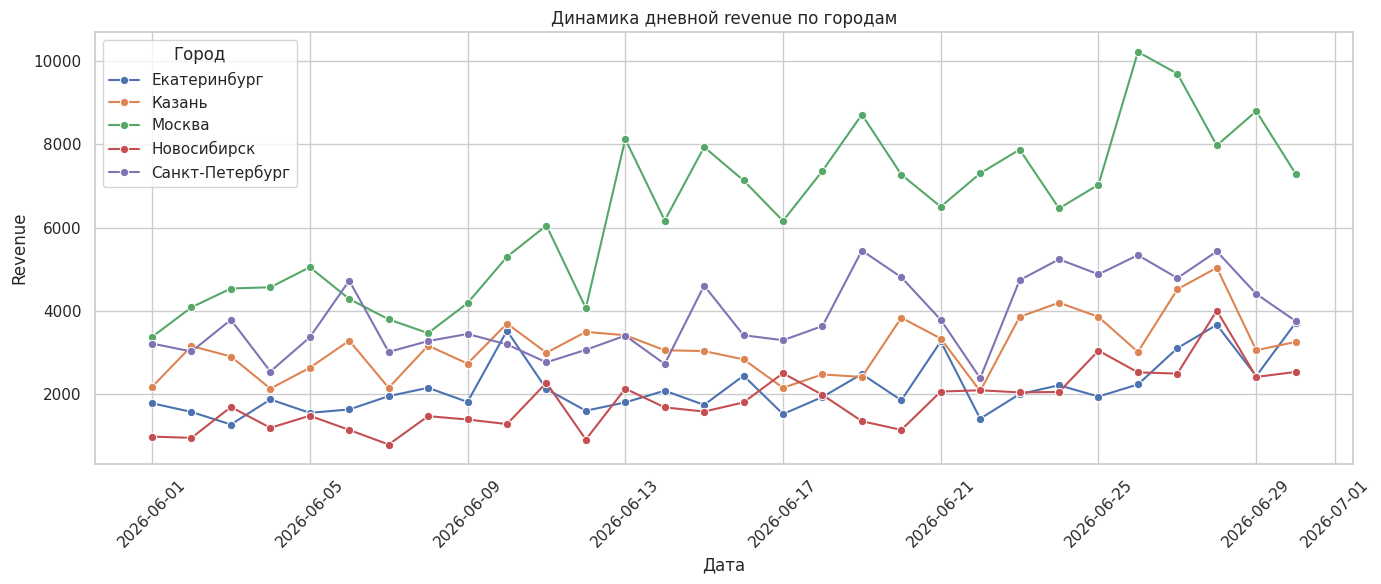

,revenue_start,revenue_end,absolute_change,relative_change,relative_change_pct
city,,,,,
Москва,29720.0,57440.0,27720.0,0.932705,93.270525
Новосибирск,8290.0,19110.0,10820.0,1.305187,130.518697
Санкт-Петербург,23710.0,33850.0,10140.0,0.427668,42.766765
Казань,18480.0,26960.0,8480.0,0.458874,45.887446
Екатеринбург,11690.0,19350.0,7660.0,0.655261,65.526091


In [ ]:
# Ваш код для подневной динамики и сравнения городов
# Данные только за июнь 2026 и только покупки
june = df[
    (df["event_timestamp"] >= "2026-06-01") &
    (df["event_timestamp"] < "2026-07-01") &
    (df["event_type"] == "purchase")
].copy()

# Дата без времени
june["date"] = june["event_timestamp"].dt.date

# Дневная выручка по городам
daily_revenue = (
    june.groupby(["date", "city"], as_index=False)["revenue"]
    .sum()
)

# График
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_revenue,
    x="date",
    y="revenue",
    hue="city",
    marker="o"
)

plt.title("Динамика дневной revenue по городам")
plt.xlabel("Дата")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.legend(title="Город")
plt.tight_layout()
plt.show()


# --- Сравнение начала и конца месяца ---

# Первые 7 дней и последние 7 дней июня
start_period = june[
    (june["event_timestamp"] >= "2026-06-01") &
    (june["event_timestamp"] < "2026-06-08")
]

end_period = june[
    (june["event_timestamp"] >= "2026-06-24") &
    (june["event_timestamp"] < "2026-07-01")
]

# Revenue по городам за каждый период
start_revenue = (
    start_period.groupby("city")["revenue"]
    .sum()
    .rename("revenue_start")
)

end_revenue = (
    end_period.groupby("city")["revenue"]
    .sum()
    .rename("revenue_end")
)

comparison = pd.concat(
    [start_revenue, end_revenue],
    axis=1
).fillna(0)

# Абсолютное изменение
comparison["absolute_change"] = (
    comparison["revenue_end"] -
    comparison["revenue_start"]
)

# Относительное изменение
comparison["relative_change"] = (
    comparison["absolute_change"] /
    comparison["revenue_start"].replace(0, pd.NA)
)

# В процентах
comparison["relative_change_pct"] = (
    comparison["relative_change"] * 100
)

comparison = comparison.sort_values(
    "absolute_change",
    ascending=False
)

comparison












### Обоснование выбора периодов

_Укажите границы периодов и объясните, почему их корректно сравнивать._

### Выводы

*Назовите лидеров абсолютного и относительного роста. Объясните, почему эти показатели могут указывать на разные города*

In [ ]:
'''
1. Лидером по абсолютному росту revenue является Москва.
Выручка в Москве значительно увеличилась к концу месяца, поэтому абсолютная разница между началом и концом месяца максимальна.
2. Лидером по относительному росту является Новосибирск.
Несмотря на меньшую начальную выручку, рост относительно начального уровня оказался выше.
'''

## Задание 3. Сравните покупателей Москвы и Казани

Сравните поведение пользователей Москвы и Казани, которые совершили хотя бы одну покупку за месяц.

Для каждого покупателя рассчитайте revenue за месяц и количество визитов. Затем сравните города по двум показателям:

- средняя revenue на покупателя
- среднее количество визитов в приложение на покупателя

Чтобы описать различия подробнее, для каждой пользовательской метрики рассчитайте среднее, медиану, дисперсию, 25-й и 75-й квантили, минимум и максимум. При желании дополните описание гистограммами или boxplot-ами.

Опишите, какие различия между покупателями Москвы и Казани вы обнаружили.

In [ ]:
# Ваш код для сравнения покупателей Москвы и Казани

# Берём только июнь 2026
june = df[
    (df["event_timestamp"] >= "2026-06-01") &
    (df["event_timestamp"] < "2026-07-01")
].copy()

# Покупатели — пользователи, совершившие хотя бы одну покупку
buyers = june[
    (june["event_type"] == "purchase") &
    (june["city"].isin(["Москва", "Казань"]))
]["user_id"].unique()

# Оставляем только покупателей Москвы и Казани
buyer_data = june[june["user_id"].isin(buyers)].copy()

# Для каждого пользователя определяем город
buyer_city = (
    buyer_data.groupby("user_id")["city"]
    .agg(lambda x: x.mode().iloc[0])
    .rename("city")
)

# Revenue каждого покупателя за месяц
user_revenue = (
    buyer_data[buyer_data["event_type"] == "purchase"]
    .groupby("user_id")["revenue"]
    .sum()
    .rename("revenue")
)

# Количество визитов каждого пользователя
# Считаем количество событий пользователя
user_visits = (
    buyer_data.groupby("user_id")
    .size()
    .rename("visits")
)

# Объединяем показатели
users = pd.concat(
    [buyer_city, user_revenue, user_visits],
    axis=1
).dropna()

# Оставляем только Москву и Казань
users = users[users["city"].isin(["Москва", "Казань"])]

# Статистики по городам
statistics = users.groupby("city")[["revenue", "visits"]].agg(
    ["mean", "median", "var",
     lambda x: x.quantile(0.25),
     lambda x: x.quantile(0.75),
     "min", "max"]
)

# Переименовываем столбцы
statistics.columns = [
    "mean", "median", "variance",
    "q25", "q75", "min", "max"
] * 2

display(statistics.round(2))














,mean,median,variance,q25,q75,min,max,mean,median,variance,q25,q75,min,max
city,,,,,,,,,,,,,,
Казань,570.24,130.0,1045242.62,110.0,140.0,0.0,5980.0,5.87,1.0,102.03,1.0,1.0,1,40
Москва,2543.47,2250.0,1877868.90,1420.0,3535.0,230.0,7040.0,24.59,24.0,61.95,19.0,29.0,9,50


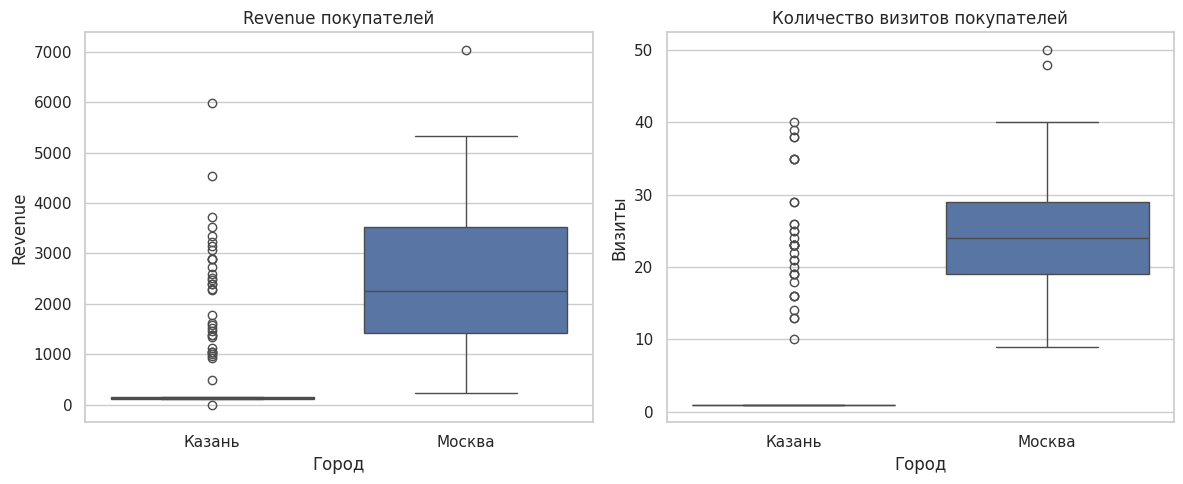

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=users, x="city", y="revenue", ax=axes[0])
axes[0].set_title("Revenue покупателей")
axes[0].set_xlabel("Город")
axes[0].set_ylabel("Revenue")

sns.boxplot(data=users, x="city", y="visits", ax=axes[1])
axes[1].set_title("Количество визитов покупателей")
axes[1].set_xlabel("Город")
axes[1].set_ylabel("Визиты")

plt.tight_layout()
plt.show()

### Выводы

*Сравните покупателей двух городов по двум метрикам. Какие выводы о различиях и сходствах распределений вы можете сделать? В описании сравните средние, медианы и ширину распределений (не обязательно использовать все параметры, акцентируйте внимание на интересных по вашему мнению моментах)*

**Покупатели Москвы и Казани** заметно различаются по обеим метрикам. По revenue у покупателей Москвы медиана значительно выше, а основной диапазон значений шире. У Казани медиана ниже, при этом распределение сильно сосредоточено около небольших значений и содержит много выбросов с высокой выручкой.

По количеству визитов медиана у Москвы также выше — около 24 визитов против примерно 1 у Казани. Распределение Москвы более компактное в основном диапазоне, тогда как у Казани большинство значений находится около минимального уровня, но присутствует много отдельных пользователей с большим количеством визитов.

Таким образом, покупатели Москвы в среднем характеризуются большей выручкой и большим количеством визитов. При этом в Казани распределения более неоднородны из-за большого количества выбросов: есть пользователи с существенно большей выручкой и числом визитов, чем у основной массы покупателей.

## Задание 4 (дополнительное). Есть ли связь между активностью пользователя и revenue?

Команда «Мякушки» хочет понять, связана ли активность пользователя в приложении с revenue.

В этом задании рассматривайте всех пользователей, которые хотя бы раз заходили в приложение за месяц.

- Постройте scatter plot количества визитов и revenue каждого пользователя
- Рассчитайте коэффициент корреляции Пирсона
- Проинтерпретируйте полученные результаты и ответьте на вопрос команды, обозначив ограничения анализа

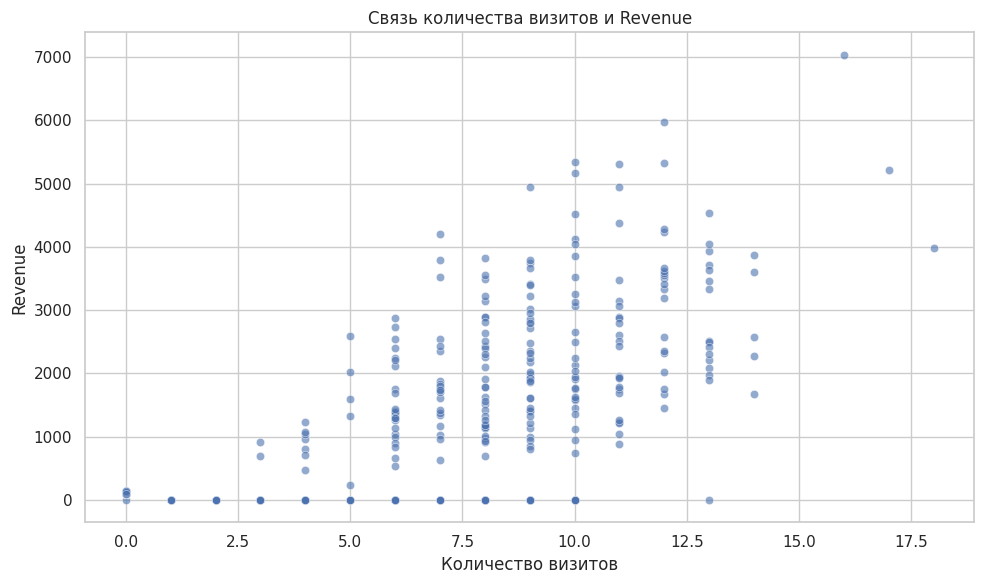

Коэффициент корреляции Пирсона: 0.621


In [ ]:
# Данные за июнь 2026
june = df[
    (df["event_timestamp"] >= "2026-06-01") &
    (df["event_timestamp"] < "2026-07-01")
].copy()

# Revenue каждого пользователя
user_revenue = (
    june[june["event_type"] == "purchase"]
    .groupby("user_id")["revenue"]
    .sum()
    .rename("revenue")
)

# Количество визитов каждого пользователя
user_visits = (
    june[june["event_type"] == "visit"]
    .groupby("user_id")
    .size()
    .rename("visits")
)

# Все пользователи, которые хотя бы раз заходили в приложение
users = pd.concat(
    [user_visits, user_revenue],
    axis=1
).fillna(0)

# Scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=users,
    x="visits",
    y="revenue",
    alpha=0.6
)

plt.title("Связь количества визитов и Revenue")
plt.xlabel("Количество визитов")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

# Коэффициент корреляции Пирсона
correlation = users["visits"].corr(users["revenue"])

print(f"Коэффициент корреляции Пирсона: {correlation:.3f}")









### Выводы

*Напишите вывод здесь*

## Перед сдачей

Перезапустите kernel и выполните все ячейки сверху вниз. Проверьте, что таблицы и графики подписаны, а выводы содержат конкретные значения, периоды и города.